# Bell's Theorem and the CHSH Inequality

Bell's Theorem is perhaps the most celebrated result in quantum information theory and lies at the center of the 2022 Nobel Prize in Physics, which was given for experimental verifications of the result John Bell proved mathematically decades before. In short, the theorem states that if a physical theory is **locally real**, then it must obey certain statistical properties; quantum systems, however, can violate these properties under the right circumstances. Here, we'll explore this idea in more detail and then demonstrate both theoretically and experimentally on a quantum computer how quantum systems misbehave.

$$\newcommand{\ket}[1]{\left|{#1}\right\rangle}$$
$$\newcommand{\bra}[1]{\left\langle{#1}\right|}$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import matplotlib as mpl
mpl.rc('xtick', direction='in', top=True)
mpl.rc('ytick', direction='in', right=True)
mpl.rc('xtick.minor', visible=True)
mpl.rc('ytick.minor', visible=True)

## Quantum Circuits

But first, a brief aside on quantum circuits, which you saw briefly in the Stern-Gerlach experiment. A functional quantum computer must meet the [DiVincenzo criteria](https://en.wikipedia.org/wiki/DiVincenzo%27s_criteria), proposed by David DiVincenzo in 2000; the criteria are:

1. A scalable physical qubit, meaning a 2-state quantum system that can feasibly be created in large numbers. Like putting transistors on a present day CPU, quantum computers need a large number of individual qubits in a network.
2. The ability to initialize all qubits to some starting state; in the example you've seen, this means that every qubit in a circuit is set to the state $\ket{0}$ at the beginning.
3. Long decoherence times; decoherence is the process by which interactions between qubits and their environments causes the qubit to lose information/be in the wrong state. A quantum computer needs to make sure that the time it takes for qubits to lose info is much longer than the time to do a computation.
4. A set of universal quantum gates; more on this below.
5. The ability to measure each qubit, these measurement values are then stored in classical bits (a traditional classical computer memory, like the RAM in the device you are currently working on).

There are [many physical systems](https://en.wikipedia.org/wiki/List_of_proposed_quantum_registers) which can be implemented to meet these criteria; [IBM](https://www.ibm.com/topics/quantum-computing#:~:text=Our%20quantum%20computers%20use%20Josephson,individual%20units%20of%20quantum%20information.) specifically uses [superconducting circuits](https://en.wikipedia.org/wiki/Superconducting_quantum_computing). 

### Quantum Gates

Mathematically, a quantum gate is an operator/matrix that acts on the quantum state of one or more qubits to alter the state in some way. The three Pauli matrices from the spin-1/2 notes are examples of single-qubit gates, though in quantum computing they are often denoted as just $X$, $Y$, or $Z$ instead of the usual $\sigma_x$, $\sigma_y$, and $\sigma_z$. 

Other single qubit gates include rotation gates which (you guessed it) rotate your state on the Bloch sphere around a given axis; these are usually denoted as $R$ (usually with a subscript to describe the angle and axis of rotation). These show up often in IBM's quantum circuit demos because IBM's hardware is only able to measure states along the $\hat{z}$-axis, so measuring on other axes is done by rotating the state so that the desired measurement becomes the $\hat{z}$-direction.

#### Practice Problem

One special single qubit gate is called the **Hadamard gate**, typically denoted $H$ (slightly unfortunate, since the Hamiltonian operator is also an $H$, but usually context makes it clear what is being referred to).

The Hadamard matrix is defined as 

$$ H = \frac1{\sqrt{2}} (X + Z) = \pmatrix{1 & 1 \\ 1 & -1}; $$

compute the result of the Hadamard operator acting on the following states, either with Python or by hand (or both).

1. $\ket{0} = \pmatrix{1 \\ 0}$
2. $\ket{1} = \pmatrix{0 \\ 1}$
3. $\ket{+} = \frac1{\sqrt{2}}\pmatrix{1 \\ 1}$

In [2]:
ket0 = np.array([1,0]);
ket1 = np.array([0,1]);
ket_plus = 1/np.sqrt(2)*np.array([1,1]);

Had = 1/np.sqrt(2)*np.array([[1,1],[1,-1]]);

print("1. H|0> = ", Had@ket0)
print("2. H|1> = ", Had@ket1)
print("3. H|0> = ", Had@ket_plus)

1. H|0> =  [0.70710678 0.70710678]
2. H|1> =  [ 0.70710678 -0.70710678]
3. H|0> =  [ 1.00000000e+00 -2.23711432e-17]


1. $ H \ket{0} = \frac1{\sqrt{2}}\pmatrix{1 & 1 \\ 1 & -1} \pmatrix{1\\0} = \frac1{\sqrt{2}}\pmatrix{1\\1} = \ket{+} $
2. $ H\ket{1} = \frac1{\sqrt{2}}\pmatrix{1 & 1 \\ 1 & -1} \pmatrix{0\\1} = \frac1{\sqrt{2}}\pmatrix{1\\-1} = \ket{-} $
3. $ H \ket{+} = \frac1{\sqrt{2}}\pmatrix{1 & 1 \\ 1 & -1} \frac1{\sqrt{2}}\pmatrix{1\\1} = \frac1{2}\pmatrix{2\\0} = \ket{0} $

***

There are also many examples of double-qubit gates which act on two qubits together; the one example we will use is called a controlled-not gate, denoted $CNOT$ or $CX$. In general, a control gate is a gate which acts on the second qubit (the **target**) only if the first qubit (the **control**) is in a particular state. In particular, the $CNOT$ gate applies an $X$ gate to the target if the control is in the state $\ket{1}$; otherwise, if the control is in the state $\ket{0}$, $CNOT$ does nothing.

As a matrix, $CNOT$ is defined as

$$ CNOT = \pmatrix{1 & 0 & 0 & 0 \\ 0 & 1 & 0 & 0 \\ 0 & 0 & 0 & 1 \\ 0 & 0 & 1 & 0}; $$

Notice the top left corner is an identity matrix, while the bottom right is a $\sigma_x$ matrix; the top left corresponds to the subspace where the control qubit is in the state $\ket{0}$, so $CNOT$ does nothing, while the bottom right is the subspace where the control is in the state $\ket{1}$, so it applies a $X$ gate. This behavior can be summarized in the truth table for $CNOT$:

| Input state | Output state |
|-------------|--------------|
| $\ket{00}$  |  $\ket{00}$  |
| $\ket{01}$  |  $\ket{01}$  |
| $\ket{10}$  |  $\ket{11}$  |
| $\ket{11}$  |  $\ket{10}$  |

#### Practice Problem

Consider a circuit with two qubits (denoted $A$ and $B$), initialized into the state 

$$ \ket{00} = \ket{0}_A \otimes \ket{0}_B = \pmatrix{1 \\ 0}_A \otimes \pmatrix{1 \\ 0}_B = \pmatrix{1 \\ 0 \\ 0 \\ 0}. $$

**NB:** Recall the symbol $\otimes$ denotes the Kronecker product, which combines two vectors into one larger vector. Here, each qubit is represented by a 2-component vector with the basis states $\ket{0}, \ket{1}$, so their joint quantum state is given by a 4-component vector with the basis states $\ket{00}, \ket{01}, \ket{10}, \ket{11}$. Look back to the linear algebra notes to refresh yourself more on Kronecker Products.

1. Ignoring the second qubit temporarily, apply a Hadamard gate to the first qubit, initially in the state $\ket{0}_A$ (or just copy this down from the previous problem).
2. Using the Kronecker product, find the new 2-qubit state by multiplying the previous result with the initial state $\ket{0}_B$ of the second qubit; the result should be a 4-component vector.
3. Apply the $CNOT$ gate to the previous 2-qubit state. The resulting state is called a **Bell Pair**; the 2 qubits have now become fully entangled, meaning that a measurement on one tells me the result of a measurement on the other. 

1. From the previous problem: $ H \ket{0}_A = \frac1{\sqrt{2}}\pmatrix{1\\1} = \ket{+}_A $
2. $ \ket{+}_A \otimes \ket{0}_B = \frac1{\sqrt{2}} \pmatrix{1\\1} \otimes \pmatrix{1\\0} = \frac1{\sqrt{2}} \pmatrix{1\\0\\1\\0} $
3. $ CNOT \left(\frac1{\sqrt{2}} \pmatrix{1\\0\\1\\0}\right) = \pmatrix{1 & 0 & 0 & 0 \\ 0 & 1 & 0 & 0 \\ 0 & 0 & 0 & 1 \\ 0 & 0 & 1 & 0} \frac1{\sqrt{2}} \pmatrix{1\\0\\1\\0} = \frac1{\sqrt{2}} \pmatrix{1\\0\\0\\1} $

In [3]:
## Start from ket0 for A
step1 = Had@ket0;
## Kronecker product result with ket0 for B
step2 = np.kron(step1, ket0);
## apply CNOT to the result
CNOT = np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]]);
step3 = CNOT@step2;

print("Final result: ", step3)

Final result:  [0.70710678 0.         0.         0.70710678]


Alternatively: we could make the Hadamard gate a 2-qubit gate by taking the matrix Kronecker product with the identity.

$$ H_2 = H \otimes \mathbb{I} = \frac1{\sqrt{2}} \pmatrix{1 & 1 \\ 1 & -1} \otimes \pmatrix{1 & 0 \\ 0 & 1} = \frac1{\sqrt{2}} \pmatrix{1 & 0 & 1 & 0 \\ 0 & 1 & 0 & 1 \\ 1 & 0 & -1 & 0 \\ 0 & 1 & 0 & -1}. $$

We can then apply this 2-qubit gate to the full initial state $\ket{00}$, then apply $CNOT$ as above:

$$ H_2 \ket{00} = \frac1{\sqrt{2}} \pmatrix{1 & 0 & 1 & 0 \\ 0 & 1 & 0 & 1 \\ 1 & 0 & -1 & 0 \\ 0 & 1 & 0 & -1} \pmatrix{1\\0\\0\\0} = \frac1{\sqrt{2}} \pmatrix{1\\0\\1\\0}. $$

This is how the setup is implemented in the section below for the CHSH inequality.

***

As a final note on quantum gates and circuits, any arbitrary quantum gate can actually be made by multiplying the right combination of single-qubit rotations and a 2-qubit entangling gate (such as $CNOT$). This means that if your computer is capable of performing single-qubit rotations about all three axes of the Bloch sphere and $CNOT$, then it is (in principle) capable of doing any quantum calculation you want; this is what the 4th DiVincenzo criteria requires.

## Local Realism

At the heart of Bell's Theorem is the idea of **local realism**. These two criteria were considered necessary for any sensible pre-quantum physical theory; in particular, Einstein and other early critics of quantum mechanics pointed to local realism as justification that quantum mechanics couldn't be a good theory. Separately, the two ideas are:

1. **Locality** is the condition that information can't travel faster than the speed of light; this is often shown visually with a light cone in a space-time diagram. The cone traces out the region of space which a light-speed signal can reach in a particular time; a force/object at the point of the cone can't influence anything outside the cone, since that would require a signal traveling faster than $c$.

2. **Realism** is the idea that objects' physical properties are determined at all times, even before or after they are measured. This idea prompted the famous "God does not play dice" quote from Einstein, since quantum mechanics suggests that physical properties are governed by probabilities, and the precise outcome of an experiment isn't determined until the experiment is done and a wave function "collapses" to a measurement outcome.

Take the Stern-Gerlach experiment as an example: if the universe were locally real, then each particle traveling through the device would be secretly "labeled" with its spin state (up/down) before the experiment, and the device simply makes this label known to the experimenter. This means a particle which measures "up" once, should *always* measure spin "up", but we have already seen this is not true! Go back to the last part of the Stern-Gerlach notes: a spin which measures "up" along the $z$-axis, then measures "right" along the $x$-axis, can then still have a 50/50 chance of measuring "up" or "down" upon a second measurement along the $z$-axis.

Bell's Theorem puts this idea of local realism to a strict, mathematical test, and provides us a metric to see whether an experiment is locally real or not (and if not, by how much?).

## Bell's Theorem

Before reading on, I would *highly* recommend watching the following videos. The first video, from [ThreeBlueOneBrown and MinutePhysics](https://www.youtube.com/watch?v=zcqZHYo7ONs), offers a bit more visual description of local realism and a clever counting/probability argument for Bell's Theorem that relies on very little quantum knowledge. The second, from [IBM QisKit](https://www.youtube.com/watch?v=9OM0jSTeeBg) takes a more modern quantum computing approach and covers just about everything in the next few paragraphs. (Optionally, [this partner video by ThreeBlueOneBrown/MinutePhysics](https://www.youtube.com/watch?v=MzRCDLre1b4) is not super relevant to this set of notes, but does cover a lot of other quantum basics very well).

Our goal here is to prove a version of Bell's Theorem known as the [Clauser-Horne-Shimony-Holt (CHSH) Inequality](https://en.wikipedia.org/wiki/CHSH_inequality); there are other versions of Bell's Theorem which use different quantum measurements and calculations to prove similar inequalities. Here we start with 2 qubits in the initial state `psi0`, given by $\ket{00} = \pmatrix{1 & 0 & 0 & 0}^\top$. From this, we'll apply the "circuit" from the previous practice problem by using a Hadamard matrix $H$ on the first qubit, then a $CNOT$ on both of them, to end up with the entangled state `psi2` below, which is our Bell pair from before.

To carry out the CHSH experiment, we'll imagine that one qubit has been assigned to Alice, and another to Bob. Each time the experiment is conducted, Alice flips a coin to decide whether to measure along either $X$ or $Z$; we'll call these $A_X$ and $A_Z$ to be clear. Bob does the same, but using two different (but still perpendicular) measurement axes, which we'll call $B_X$ and $B_Z$. Each time, Alice and Bob measure either $\pm 1$; then, the experiment is repeated ad nauseam so that we can take averages. 

There are two related quantities of interest here: 

$$ S_1 = (A_X-A_Z)B_X + (A_X+A_Z)B_Z;\ S_2 = A_X(B_X-B_Z) + A_Z(B_X+B_Z); $$ 

since each of the 4 measurements is always $\pm 1$, then you can convince yourself that one term in each $S_1$ and $S_2$ is always 0, and the other is $\pm 2$. Therefore, averaged over many experiments, we expect that 

$$ |S_1| \leq 2, |S_2| \leq 2. $$

Expanding out the terms in each, and inserting expectation values for the averaging, the quantum things we want to calculate are:

$$ \langle S_1 \rangle = \langle A_X B_X \rangle - \langle A_Z B_X \rangle + \langle A_X B_Z \rangle + \langle A_Z B_Z \rangle; $$

$$ \langle S_2 \rangle = \langle A_X B_X \rangle - \langle A_X B_Z \rangle + \langle A_Z B_X \rangle + \langle A_Z B_Z \rangle. $$

In the next few code cells, I'm just going to compute all these expectation values the way that you're familiar: defining vectors for states, matrices for operators, then computing inner products.

In [4]:
## Identity matrix
Id = np.array([[1,0],[0,1]]);
## Hadamard matrix
Had = 1/np.sqrt(2)*np.array([[1,1],[1,-1]]);
## need 2-qubit version of Hadamard, made by Kronecker product of Had with Id
Had_double = np.kron(Had, Id);

## CNOT matrix
CNOT = np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]]);

def Ry(theta):
    '''
    Returns 2-qubit gate which rotates the second qubit by an 
    an angle theta (in radians) about the y-axis.
    '''
    Ry_single = np.array([[np.cos(theta/2), -np.sin(theta/2)],[np.sin(theta/2),np.cos(theta/2)]])
    return np.kron(Id, Ry_single);

In [5]:
## Here is our "quantum circuit"
## Step 0: initialize
psi0 = np.array([1,0,0,0]);

## Step 1: Hadamard gate on first qubit in psi0
psi1 = Had_double@psi0;

## Step 2: Apply CNOT to entangle qubits
psi2 = CNOT@psi1; ## this should be the same as your answer to the previous problem!

## Step 3: Rotate basis of Bob's qubit by some angle theta
theta = np.pi/8; ## can put in any angle here (in radians)
psi3 = Ry(theta)@psi2;

## Now for the measurements: both Alice and Bob will measure along X and Z,
## but since Bob's qubit has been rotated, Bob effectively measures along 
## two axes rotated an angle 'theta' away from X and Z
PauliX = np.array([[0,1],[1,0]]);
PauliZ = np.array([[1,0],[0,-1]]);

XX = np.kron(PauliX, PauliX);
XZ = np.kron(PauliX, PauliZ);
ZX = np.kron(PauliZ, PauliX);
ZZ = np.kron(PauliZ, PauliZ);

## Computing expectation values in the state psi3
E_XX = np.inner(psi3, XX@psi3);
E_XZ = np.inner(psi3, XZ@psi3);
E_ZX = np.inner(psi3, ZX@psi3);
E_ZZ = np.inner(psi3, ZZ@psi3);

## Compute the two CHSH quantities
S1 = E_XX + E_XZ - E_ZX + E_ZZ;
S2 = E_XX - E_XZ + E_ZX + E_ZZ;

## one of these should be larger than 2!
print("First CHSH quantity: ", np.abs(S1))
print("Second CHSH quantity: ", np.abs(S2))

First CHSH quantity:  1.0823922002923938
Second CHSH quantity:  2.6131259297527523


### Practice Problem

Compute the CHSH quantities $S1$ and $S2$ as shown above for (at least 25) $\theta$ values between $0$ and $2\pi$ and plot them both as function of $\theta$ on the same axes.

Make sure your plot has the following:
 - **Use different colors and line styles for the two lines (i.e. one solid, one dashed).** Different colors are helpful to differentiate data in plots, but its also useful to use different markers or line styles in case your data is viewed by anyone with color blindness, or printed in grayscale.
 - **Make sure to include a legend with labels for the lines.**

Added challenges:
 - **Add horizontal gridlines and tick labels at the following values: $\{-2\sqrt{2},\ -2,\ 0,\ 2,\ 2\sqrt{2}\}$**
 - **Add vertical gridlines spaced every $\pi/4$, with appropriate tick labels.**
 - **Use different colors to highlight regions on the plot where either $S_1$ or $S_2$ violate the inequality.** As a hint in the right direction, look up the documentation for `ax.axvspan`.

Don't be afraid to search online for any plotting options/syntax that you don't know, and feel free to text/email me with questions and I'll point you in the right direction. If you can, take the time to make this plot look great and ready for publication - it might be worth including on your final poster.

In [15]:
theta_pts = 100;
theta_arr = np.linspace(0, 2*np.pi, theta_pts);

S1_arr = np.zeros(theta_pts);
S2_arr = np.zeros(theta_pts);
for t in range(theta_pts):
    theta = theta_arr[t];
    
    ## Rotate basis of Bob's qubit by some angle theta
    psi3 = Ry(theta)@psi2;
    
    ## Computing expectation values in the state psi3
    E_XX = np.inner(psi3, XX@psi3);
    E_XZ = np.inner(psi3, XZ@psi3);
    E_ZX = np.inner(psi3, ZX@psi3);
    E_ZZ = np.inner(psi3, ZZ@psi3);
    
    ## Compute the two CHSH quantities
    S1_arr[t] = E_XX + E_XZ - E_ZX + E_ZZ;
    S2_arr[t] = E_XX - E_XZ + E_ZX + E_ZZ;

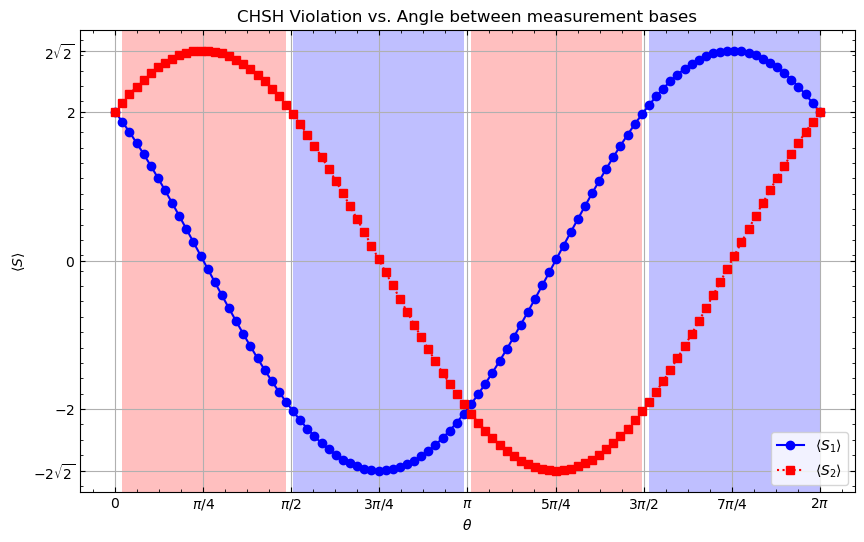

In [16]:
chsh_fig = plt.figure(figsize=(10,6));
chsh_ax = chsh_fig.add_subplot(111);
chsh_ax.set_xlabel(r"$\theta$");
chsh_ax.set_ylabel(r"$\langle S \rangle$");
chsh_ax.set_title("CHSH Violation vs. Angle between measurement bases");
chsh_ax.plot(theta_arr, S1_arr, 'bo-', label = r"$\langle S_1 \rangle$");
chsh_ax.plot(theta_arr, S2_arr, 'rs:', label = r"$\langle S_2 \rangle$");
chsh_ax.legend(loc='lower right');

xticks = np.arange(0,2*np.pi+0.1, np.pi/4);
xtick_labels = [r"$0$", r"$\pi/4$", r"$\pi/2$", r"$3\pi/4$", r"$\pi$", r"$5\pi/4$", r"$3\pi/2$", r"$7\pi/4$", r"$2\pi$"];
yticks = np.array([-2*np.sqrt(2), -2, 0, 2, 2*np.sqrt(2)]);
ytick_labels = [r"$-2\sqrt{2}$", r"$-2$", r"$0$", r"$2$", r"$2\sqrt{2}$"];

chsh_ax.set_xticks(xticks, xtick_labels);
chsh_ax.set_yticks(yticks, ytick_labels);
chsh_ax.grid(axis='both');

for j in range(len(theta_arr)-1):
    if np.abs(S1_arr[j])>=2 and np.abs(S1_arr[j+1])>=2:
        chsh_ax.axvspan(theta_arr[j], theta_arr[j+1], ymin=-3, ymax=3, facecolor='b', alpha=0.25);
    if np.abs(S2_arr[j])>=2 and np.abs(S2_arr[j+1])>=2:
        chsh_ax.axvspan(theta_arr[j], theta_arr[j+1], ymin=-3, ymax=3, facecolor='r', alpha=0.25);

### Practice Problem

Now that you've worked things out on your own, you can repeat this experiment on an IBM quantum device by following the [tutorial here](https://learning.quantum.ibm.com/tutorial/chsh-inequality). You can run it in a web browser by signing in to your IBM account; you could also make a new Jupyter notebook and copy the code segments from the webpage into that notebook if you'd like to experiment more with it (or if you're having trouble getting it to work in the webpage). If everything goes as planned, the end result should be a plot a *lot* like the one you just made.

## Summary

First, we have seen that if physics is locally real, then we can argue that certain measurable quantities must obey certain statistical properties; we have the example of the CHSH Inequality, but there are many other similar results. Second, we showed that our quantum theory of spin violates this inequality by using a simple setup of two entangled spins. This violation has been proven experimentally by [Aspect, Clauser, and Zeilinger](https://www.nobelprize.org/prizes/physics/2022/summary/) (and subsequently many others) by measuring entangled photon polarization states which are spatially separated, but measured at the exact same time. This shows definitively that physics might be local, or might be real, but can never be both; most scientists today would agree that locality still holds up, but realism is not compatible with our experimental observations.

Next, we're going to take a brief break from quantum weirdness and discuss a simple, classical physics model called the Ising model. We'll use this model to introduce the basics of phase transitions. Eventually, our goal will be to make a similar plot to the CHSH plot shown in the IBM example showing the violation of the inequality as a function of a parameter in our model of a quantum magnet, in order to understand better the behavior of quantum entanglement as it naturally arises in this magnet.